In [ ]:

# ==========================================
# FERTILIZER RECOMMENDATION SYSTEM
# STEP 1: DATA COLLECTION & INITIAL ANALYSIS
# ==========================================

# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

# 2. Load Dataset
url = "https://huggingface.co/datasets/kaifahmad/Fertilizer-Prediction/resolve/main/Fertilizer%20Prediction.csv"

df = pd.read_csv(url)

print("\nDataset loaded successfully!")

# 3. Display First 5 Rows
print("\n----- First 5 Rows -----")
display(df.head())

# 4. Dataset Shape
print("\n----- Dataset Shape -----")
print(df.shape)

# 5. Column Names
print("\n----- Column Names -----")
print(df.columns.tolist())

# 6. Dataset Information
print("\n----- Dataset Information -----")
df.info()

# 7. Statistical Summary
print("\n----- Statistical Summary -----")
display(df.describe())

# 8. Check Missing Values
print("\n----- Missing Values -----")
print(df.isnull().sum())

# 9. Check Duplicate Records
print("\n----- Duplicate Records -----")
print("Total duplicates:", df.duplicated().sum())

# 10. Unique Fertilizer Categories
print("\n----- Fertilizer Categories -----")
print(df["Fertilizer Name"].unique())

# 11. Count Each Fertilizer Category
print("\n----- Fertilizer Category Counts -----")
print(df["Fertilizer Name"].value_counts())

print("\n===== INITIAL DATA ANALYSIS COMPLETED =====")


Libraries imported successfully!

Dataset loaded successfully!

----- First 5 Rows -----


,Temparature,Humidity,Moisture,Soil Type,Crop Type,Nitrogen,Potassium,Phosphorous,Fertilizer Name
0,26,52,38,Sandy,Maize,37,0,0,Urea
1,29,52,45,Loamy,Sugarcane,12,0,36,DAP
2,34,65,62,Black,Cotton,7,9,30,14-35-14
3,32,62,34,Red,Tobacco,22,0,20,28-28
4,28,54,46,Clayey,Paddy,35,0,0,Urea



----- Dataset Shape -----
(99, 9)

----- Column Names -----
['Temparature', 'Humidity ', 'Moisture', 'Soil Type', 'Crop Type', 'Nitrogen', 'Potassium', 'Phosphorous', 'Fertilizer Name']

----- Dataset Information -----
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99 entries, 0 to 98
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Temparature      99 non-null     int64 
 1   Humidity         99 non-null     int64 
 2   Moisture         99 non-null     int64 
 3   Soil Type        99 non-null     object
 4   Crop Type        99 non-null     object
 5   Nitrogen         99 non-null     int64 
 6   Potassium        99 non-null     int64 
 7   Phosphorous      99 non-null     int64 
 8   Fertilizer Name  99 non-null     object
dtypes: int64(6), object(3)
memory usage: 7.1+ KB

----- Statistical Summary -----


,Temparature,Humidity,Moisture,Nitrogen,Potassium,Phosphorous
count,99.000000,99.000000,99.000000,99.000000,99.000000,99.000000
mean,30.282828,59.151515,43.181818,18.909091,3.383838,18.606061
std,3.502304,5.840331,11.271568,11.599693,5.814667,13.476978
min,25.000000,50.000000,25.000000,4.000000,0.000000,0.000000
25%,28.000000,54.000000,34.000000,10.000000,0.000000,9.000000
50%,30.000000,60.000000,41.000000,13.000000,0.000000,19.000000
75%,33.000000,64.000000,50.500000,24.000000,7.500000,30.000000
max,38.000000,72.000000,65.000000,42.000000,19.000000,42.000000



----- Missing Values -----
Temparature        0
Humidity           0
Moisture           0
Soil Type          0
Crop Type          0
Nitrogen           0
Potassium          0
Phosphorous        0
Fertilizer Name    0
dtype: int64

----- Duplicate Records -----
Total duplicates: 0

----- Fertilizer Categories -----
['Urea' 'DAP' '14-35-14' '28-28' '17-17-17' '20-20' '10-26-26']

----- Fertilizer Category Counts -----
Fertilizer Name
Urea        22
DAP         18
28-28       17
14-35-14    14
20-20       14
17-17-17     7
10-26-26     7
Name: count, dtype: int64

===== INITIAL DATA ANALYSIS COMPLETED =====


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:

# ==========================================
# STEP 5: DATA CLEANING & PREPROCESSING
# ==========================================

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

# 1. Create a copy of original dataset
data = df.copy()

# 2. Clean column names
data.columns = data.columns.str.strip()

# 3. Remove duplicate records
data.drop_duplicates(inplace=True)

# 4. Handle missing values
for column in data.columns:

    if data[column].dtype == "object":
        data[column] = data[column].fillna(
            data[column].mode()[0]
        )
    else:
        data[column] = data[column].fillna(
            data[column].median()
        )

# 5. Separate input and target
X = data.drop("Fertilizer Name", axis=1)
y = data["Fertilizer Name"]

# 6. Encode categorical input columns
encoders = {}

for column in X.select_dtypes(include="object").columns:

    le = LabelEncoder()
    X[column] = le.fit_transform(X[column].astype(str))
    encoders[column] = le

# 7. Encode target variable
target_encoder = LabelEncoder()
y = target_encoder.fit_transform(y)

# 8. Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 9. Display results
print("DATA PREPROCESSING COMPLETED!")
print("--------------------------------")

print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", data.shape)

print("\nInput Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nEncoded Input Features:")
display(X.head())

print("\nPreprocessing completed successfully!")


DATA PREPROCESSING COMPLETED!
--------------------------------
Original Dataset Shape: (99, 9)
Cleaned Dataset Shape: (99, 9)

Input Features Shape: (99, 8)
Target Variable Shape: (99,)

Training Data: (79, 8)
Testing Data: (20, 8)

Encoded Input Features:


,Temparature,Humidity,Moisture,Soil Type,Crop Type,Nitrogen,Potassium,Phosphorous
0,26,52,38,4,3,37,0,0
1,29,52,45,2,8,12,0,36
2,34,65,62,0,1,7,9,30
3,32,62,34,3,9,22,0,20
4,28,54,46,1,6,35,0,0



Preprocessing completed successfully!


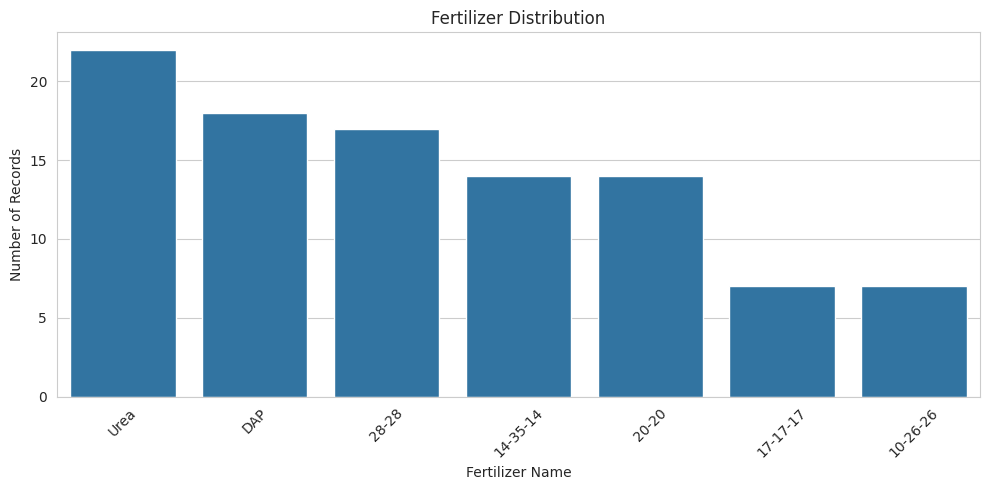

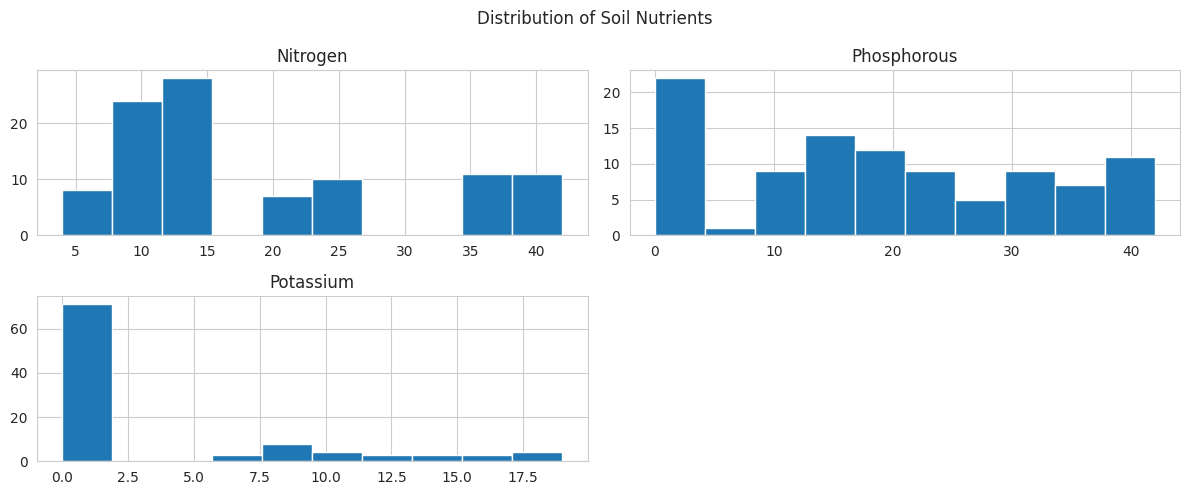

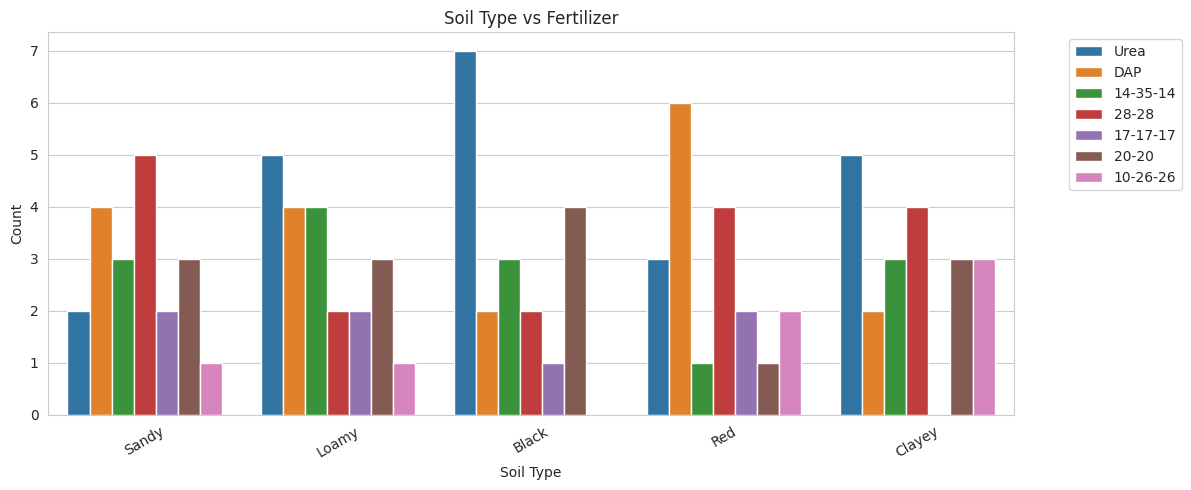

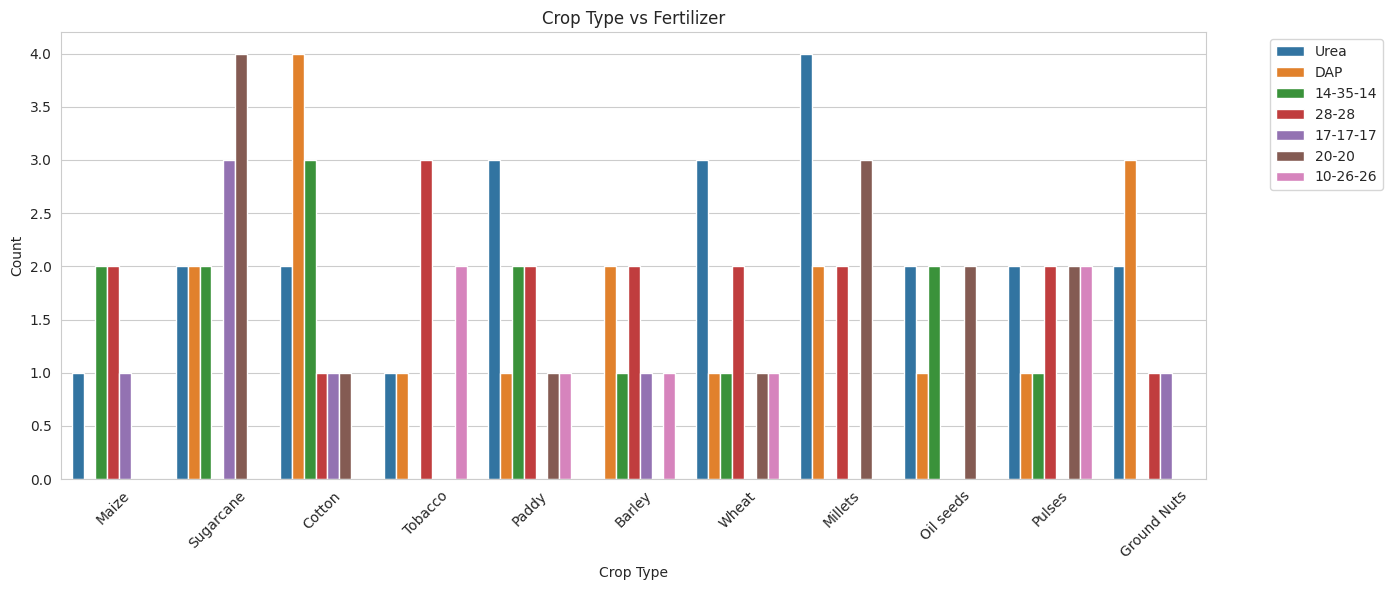

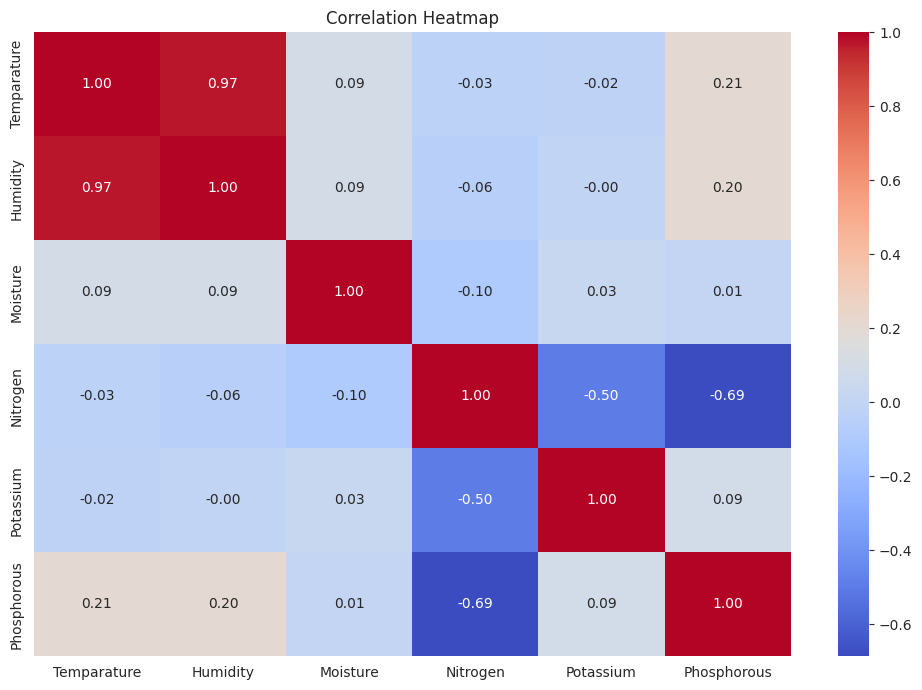


Average Soil Nutrient Values:


,Average Value
Nitrogen,18.909091
Phosphorous,18.606061
Potassium,3.383838



EDA COMPLETED SUCCESSFULLY!


In [ ]:

# ==========================================
# STEP 6: EXPLORATORY DATA ANALYSIS (EDA)
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_style("whitegrid")

# 1. Fertilizer Distribution
plt.figure(figsize=(10, 5))

sns.countplot(
    data=data,
    x="Fertilizer Name",
    order=data["Fertilizer Name"].value_counts().index
)

plt.title("Fertilizer Distribution")
plt.xlabel("Fertilizer Name")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 2. Nitrogen, Phosphorus and Potassium Distribution
nutrients = ["Nitrogen", "Phosphorous", "Potassium"]

data[nutrients].hist(figsize=(12, 5), bins=10)

plt.suptitle("Distribution of Soil Nutrients")
plt.tight_layout()
plt.show()


# 3. Soil Type vs Fertilizer
plt.figure(figsize=(12, 5))

sns.countplot(
    data=data,
    x="Soil Type",
    hue="Fertilizer Name"
)

plt.title("Soil Type vs Fertilizer")
plt.xlabel("Soil Type")
plt.ylabel("Count")
plt.xticks(rotation=30)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


# 4. Crop Type vs Fertilizer
plt.figure(figsize=(14, 6))

sns.countplot(
    data=data,
    x="Crop Type",
    hue="Fertilizer Name"
)

plt.title("Crop Type vs Fertilizer")
plt.xlabel("Crop Type")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


# 5. Correlation Heatmap
numeric_data = data.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


# 6. Average Nutrient Values
print("\nAverage Soil Nutrient Values:")
display(data[nutrients].mean().to_frame("Average Value"))

print("\nEDA COMPLETED SUCCESSFULLY!")


In [ ]:

# ==========================================
# STEP 7: FEATURE ENGINEERING
# ==========================================

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# 1. Create a copy of cleaned dataset
feature_data = data.copy()

# 2. Create nutrient level indicators
# These are simple dataset-based indicators,
# not scientifically validated deficiency limits.

for nutrient in ["Nitrogen", "Phosphorous", "Potassium"]:

    median_value = feature_data[nutrient].median()

    feature_data[nutrient + "_Level"] = (
        feature_data[nutrient] < median_value
    ).astype(int)

# 3. Separate input and target
X = feature_data.drop("Fertilizer Name", axis=1)
y = feature_data["Fertilizer Name"]

# 4. Encode categorical input features
encoders = {}

for column in X.select_dtypes(include="object").columns:

    le = LabelEncoder()
    X[column] = le.fit_transform(X[column].astype(str))
    encoders[column] = le

# 5. Encode target variable
target_encoder = LabelEncoder()
y = target_encoder.fit_transform(y)

# 6. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 7. Apply feature scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 8. Display results
print("FEATURE ENGINEERING COMPLETED!")
print("--------------------------------")

print("\nNew Features:")
print(feature_data.columns.tolist())

print("\nTraining Data Shape:", X_train_scaled.shape)
print("Testing Data Shape:", X_test_scaled.shape)

print("\nFeature Data Preview:")
display(feature_data.head())

print("\nScaled Training Data Preview:")
display(pd.DataFrame(
    X_train_scaled,
    columns=X.columns
).head())

print("\nFeature Engineering Completed Successfully!")


FEATURE ENGINEERING COMPLETED!
--------------------------------

New Features:
['Temparature', 'Humidity', 'Moisture', 'Soil Type', 'Crop Type', 'Nitrogen', 'Potassium', 'Phosphorous', 'Fertilizer Name', 'Nitrogen_Level', 'Phosphorous_Level', 'Potassium_Level']

Training Data Shape: (79, 11)
Testing Data Shape: (20, 11)

Feature Data Preview:


,Temparature,Humidity,Moisture,Soil Type,Crop Type,Nitrogen,Potassium,Phosphorous,Fertilizer Name,Nitrogen_Level,Phosphorous_Level,Potassium_Level
0,26,52,38,Sandy,Maize,37,0,0,Urea,0,1,0
1,29,52,45,Loamy,Sugarcane,12,0,36,DAP,1,0,0
2,34,65,62,Black,Cotton,7,9,30,14-35-14,1,0,0
3,32,62,34,Red,Tobacco,22,0,20,28-28,0,0,0
4,28,54,46,Clayey,Paddy,35,0,0,Urea,0,1,0



Scaled Training Data Preview:


,Temparature,Humidity,Moisture,Soil Type,Crop Type,Nitrogen,Potassium,Phosphorous,Nitrogen_Level,Phosphorous_Level,Potassium_Level
0,1.615182,0.109561,0.027438,1.363387,-0.344290,-0.310316,-0.594993,1.674834,-0.891883,-0.962720,0.0
1,-0.414808,-0.236651,2.014416,-1.363387,-1.304253,-0.397558,-0.594993,1.221711,-0.891883,-0.962720,0.0
2,1.035185,0.975090,1.020927,0.000000,1.575635,1.696249,-0.594993,-1.421506,-0.891883,1.038724,0.0
3,-0.414808,-0.236651,1.653147,0.000000,-1.304253,-0.659284,-0.594993,1.448273,1.121224,-0.962720,0.0
4,0.165189,0.455772,1.833781,0.681693,-1.304253,-0.659284,1.448680,-0.288699,1.121224,1.038724,0.0



Feature Engineering Completed Successfully!



Training: Decision Tree
Accuracy: 95.0 %

Classification Report:
              precision    recall  f1-score   support

    10-26-26       1.00      1.00      1.00         1
    14-35-14       1.00      0.67      0.80         3
    17-17-17       0.50      1.00      0.67         1
       20-20       1.00      1.00      1.00         3
       28-28       1.00      1.00      1.00         3
         DAP       1.00      1.00      1.00         4
        Urea       1.00      1.00      1.00         5

    accuracy                           0.95        20
   macro avg       0.93      0.95      0.92        20
weighted avg       0.97      0.95      0.95        20


Training: Random Forest
Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

    10-26-26       1.00      1.00      1.00         1
    14-35-14       1.00      1.00      1.00         3
    17-17-17       1.00      1.00      1.00         1
       20-20       1.00      1.00      1.00         3

,Model,Accuracy
1,Random Forest,100.0
0,Decision Tree,95.0
2,SVM,95.0



Best Model: Random Forest


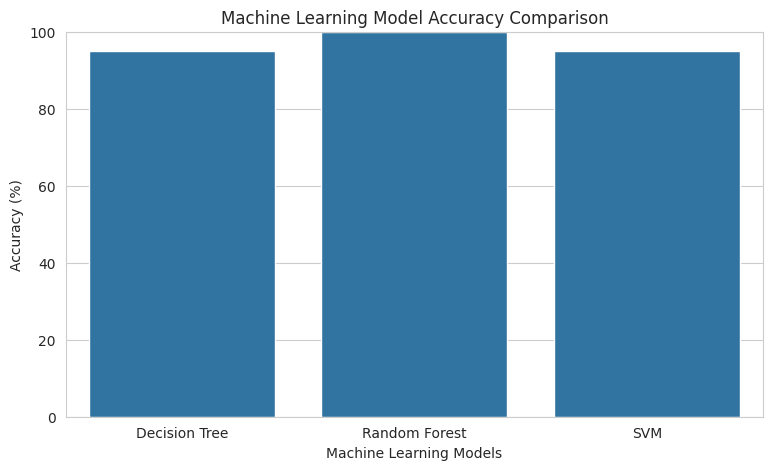


MODEL TRAINING COMPLETED!


In [ ]:

# ==========================================
# STEP 8: MACHINE LEARNING MODEL TRAINING
# ==========================================

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

# 1. Create Machine Learning Models

models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "SVM": SVC(
        kernel="rbf",
        C=1.0,
        random_state=42
    )
}

# 2. Train and Evaluate Models

results = []

trained_models = {}

for name, model in models.items():

    print("\n================================")
    print("Training:", name)
    print("================================")

    # Train model
    model.fit(X_train_scaled, y_train)

    # Make predictions
    y_pred = model.predict(X_test_scaled)

    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)

    # Store results
    results.append({
        "Model": name,
        "Accuracy": accuracy * 100
    })

    trained_models[name] = model

    print("Accuracy:", round(accuracy * 100, 2), "%")

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        labels=np.arange(len(target_encoder.classes_)),
        target_names=target_encoder.classes_,
        zero_division=0
    ))

# 3. Compare Model Performance

results_df = pd.DataFrame(results)

print("\n===== MODEL COMPARISON =====")
display(results_df.sort_values(
    by="Accuracy",
    ascending=False
))

# 4. Find Best Performing Model

best_model_name = results_df.loc[
    results_df["Accuracy"].idxmax(),
    "Model"
]

best_model = trained_models[best_model_name]

print("\nBest Model:", best_model_name)

# 5. Visualize Model Accuracy

plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Machine Learning Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.show()

print("\nMODEL TRAINING COMPLETED!")


In [ ]:
# Display all available columns
print("Dataset Columns:")
print(df.columns.tolist())

# Display numerical columns
print("\nNumerical Columns:")
print(df.select_dtypes(include=np.number).columns.tolist())

# Display first 5 rows
print("\nFirst 5 Rows:")
display(df.head())

# Display dataset information
print("\nDataset Information:")
df.info()

Dataset Columns:
['Temparature', 'Humidity ', 'Moisture', 'Soil Type', 'Crop Type', 'Nitrogen', 'Potassium', 'Phosphorous', 'Fertilizer Name']

Numerical Columns:
['Temparature', 'Humidity ', 'Moisture', 'Nitrogen', 'Potassium', 'Phosphorous']

First 5 Rows:


,Temparature,Humidity,Moisture,Soil Type,Crop Type,Nitrogen,Potassium,Phosphorous,Fertilizer Name
0,26,52,38,Sandy,Maize,37,0,0,Urea
1,29,52,45,Loamy,Sugarcane,12,0,36,DAP
2,34,65,62,Black,Cotton,7,9,30,14-35-14
3,32,62,34,Red,Tobacco,22,0,20,28-28
4,28,54,46,Clayey,Paddy,35,0,0,Urea



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99 entries, 0 to 98
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Temparature      99 non-null     int64 
 1   Humidity         99 non-null     int64 
 2   Moisture         99 non-null     int64 
 3   Soil Type        99 non-null     object
 4   Crop Type        99 non-null     object
 5   Nitrogen         99 non-null     int64 
 6   Potassium        99 non-null     int64 
 7   Phosphorous      99 non-null     int64 
 8   Fertilizer Name  99 non-null     object
dtypes: int64(6), object(3)
memory usage: 7.1+ KB


In [ ]:
# Check dataset columns
print("All Columns:")
print(df.columns.tolist())

# Check numerical columns
print("\nNumerical Columns:")
print(df.select_dtypes(include=np.number).columns.tolist())

# Check target column
print("\nFertilizer Name:")
print(df["Fertilizer Name"].head())

All Columns:
['Temparature', 'Humidity ', 'Moisture', 'Soil Type', 'Crop Type', 'Nitrogen', 'Potassium', 'Phosphorous', 'Fertilizer Name']

Numerical Columns:
['Temparature', 'Humidity ', 'Moisture', 'Nitrogen', 'Potassium', 'Phosphorous']

Fertilizer Name:
0        Urea
1         DAP
2    14-35-14
3       28-28
4        Urea
Name: Fertilizer Name, dtype: object


In [ ]:
import pandas as pd
import numpy as np

# Possible fertilizer quantity column names
possible_targets = [
    "Fertilizer Quantity",
    "Fertilizer_Quantity",
    "Quantity",
    "Dosage",
    "Dose",
    "Fertilizer Rate",
    "Rate (kg/ha)"
]

# Find matching target column
target_column = next(
    (col for col in df.columns
     if col.strip().lower() in [x.lower() for x in possible_targets]),
    None
)

if target_column:
    print("Target column found:", target_column)
    print("\nTarget column details:")
    print(df[target_column].describe())
else:
    print("No fertilizer quantity column found.")
    print("\nAvailable columns:")
    print(df.columns.tolist())
    print("\nWe need a dataset containing actual fertilizer dosage")
    print("values (for example, kg/hectare) before predicting quantity.")

No fertilizer quantity column found.

Available columns:
['Temparature', 'Humidity ', 'Moisture', 'Soil Type', 'Crop Type', 'Nitrogen', 'Potassium', 'Phosphorous', 'Fertilizer Name']

We need a dataset containing actual fertilizer dosage
values (for example, kg/hectare) before predicting quantity.


In [ ]:
import pandas as pd
import numpy as np

# Display dataset columns
print("Dataset Columns:")
for col in df.columns:
    print("-", col)

# Display numerical columns
print("\nNumerical Columns:")
print(df.select_dtypes(include=np.number).columns.tolist())

# Display dataset sample
print("\nDataset Sample:")
display(df.head(10))

# Display target information
print("\nFertilizer Name Distribution:")
print(df["Fertilizer Name"].value_counts())

Dataset Columns:
- Temparature
- Humidity 
- Moisture
- Soil Type
- Crop Type
- Nitrogen
- Potassium
- Phosphorous
- Fertilizer Name

Numerical Columns:
['Temparature', 'Humidity ', 'Moisture', 'Nitrogen', 'Potassium', 'Phosphorous']

Dataset Sample:


,Temparature,Humidity,Moisture,Soil Type,Crop Type,Nitrogen,Potassium,Phosphorous,Fertilizer Name
0,26,52,38,Sandy,Maize,37,0,0,Urea
1,29,52,45,Loamy,Sugarcane,12,0,36,DAP
2,34,65,62,Black,Cotton,7,9,30,14-35-14
3,32,62,34,Red,Tobacco,22,0,20,28-28
4,28,54,46,Clayey,Paddy,35,0,0,Urea
5,26,52,35,Sandy,Barley,12,10,13,17-17-17
6,25,50,64,Red,Cotton,9,0,10,20-20
7,33,64,50,Loamy,Wheat,41,0,0,Urea
8,30,60,42,Sandy,Millets,21,0,18,28-28
9,29,58,33,Black,Oil seeds,9,7,30,14-35-14



Fertilizer Name Distribution:
Fertilizer Name
Urea        22
DAP         18
28-28       17
14-35-14    14
20-20       14
17-17-17     7
10-26-26     7
Name: count, dtype: int64


In [ ]:
# STEP 10: LINEAR REGRESSION MODEL

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Select numerical columns
numeric_df = df.select_dtypes(include=np.number).copy()

# Check whether Soil Moisture exists
if "Moisture" in numeric_df.columns:
    target = "Moisture"
elif "Soil Moisture" in numeric_df.columns:
    target = "Soil Moisture"
else:
    print("Soil Moisture column not found.")
    print("Available numerical columns:", numeric_df.columns.tolist())
    target = None

if target:
    # Remove rows with missing values
    numeric_df = numeric_df.dropna()

    # Input and target
    X = numeric_df.drop(columns=[target])
    y = numeric_df[target]

    # Split dataset
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    # Train model
    model = LinearRegression()
    model.fit(X_train, y_train)

    # Predictions
    y_pred = model.predict(X_test)

    # Evaluation
    print("Linear Regression Model Results")
    print("--------------------------------")
    print("MAE:", mean_absolute_error(y_test, y_pred))
    print("MSE:", mean_squared_error(y_test, y_pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
    print("R2 Score:", r2_score(y_test, y_pred))

    print("\nActual vs Predicted:")
    print(pd.DataFrame({
        "Actual Moisture": y_test.values,
        "Predicted Moisture": y_pred
    }).head(10))

Linear Regression Model Results
--------------------------------
MAE: 10.816221077506237
MSE: 193.09422987583167
RMSE: 13.895834983038323
R2 Score: -0.22919491931906344

Actual vs Predicted:
   Actual Moisture  Predicted Moisture
0               64           43.238995
1               30           45.622635
2               27           45.803479
3               65           36.912244
4               43           40.104288
5               44           43.099670
6               35           37.604274
7               34           42.762614
8               28           42.022789
9               38           37.530441


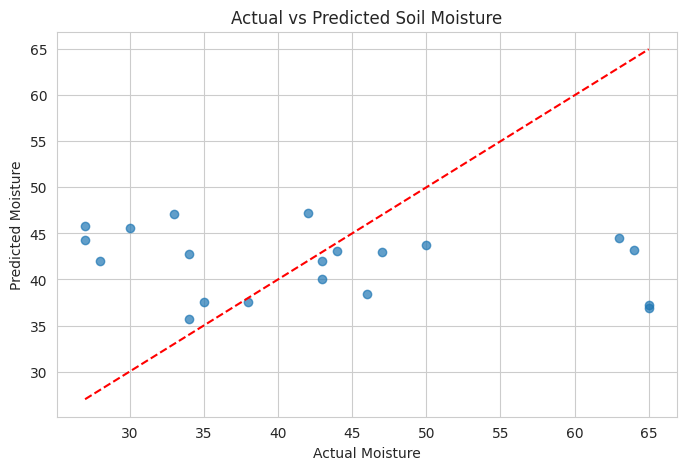

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Actual vs Predicted Graph
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.7)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Moisture")
plt.ylabel("Predicted Moisture")
plt.title("Actual vs Predicted Soil Moisture")

plt.grid(True)
plt.show()

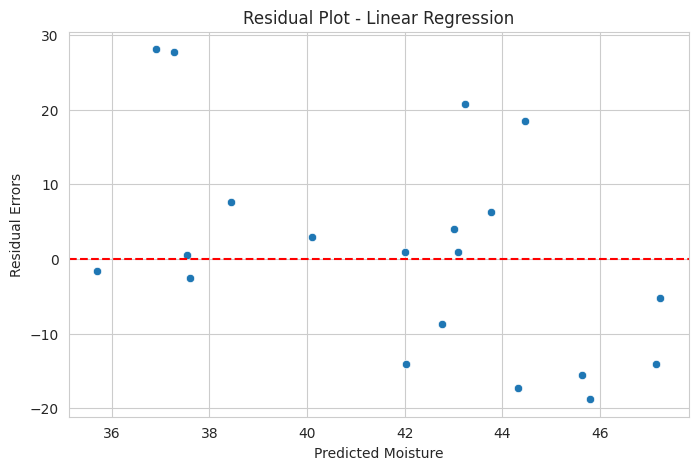

In [ ]:
# Calculate residual errors
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

sns.scatterplot(x=y_pred, y=residuals)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Moisture")
plt.ylabel("Residual Errors")
plt.title("Residual Plot - Linear Regression")

plt.grid(True)
plt.show()

In [ ]:
# STEP 13: TEST WITH NEW INPUT

# Check if prerequisite variables from Step 10 exist in current session
if 'X_test' not in globals() or 'model' not in globals():
    print("Error: Prerequisite variables 'X_test' or 'model' are not defined.")
    print("Please run the 'STEP 10: LINEAR REGRESSION MODEL' cell first to train the model and split the data!")
else:
    # Take one sample from the test dataset
    sample_input = X_test.iloc[[0]]

    # Predict soil moisture
    predicted_moisture = model.predict(sample_input)

    print("New Soil Input:")
    display(sample_input)

    print("Predicted Soil Moisture:", round(predicted_moisture[0], 2))
    print("\nModel Test Completed Successfully!")

New Soil Input:


,Temparature,Humidity,Nitrogen,Potassium,Phosphorous
62,34,65,24,0,20


Predicted Soil Moisture: 43.24

Model Test Completed Successfully!


In [ ]:
import joblib
from google.colab import files

# Check if the model is trained and defined in the current session
if 'model' not in globals():
    print("Error: The variable 'model' is not defined.")
    print("Please run the 'STEP 10: LINEAR REGRESSION MODEL' cell first to train and define your model before saving!")
else:
    # Save trained model
    joblib.dump(model, "linear_regression_model.pkl")
    print("Model saved successfully!")

    # Download model
    files.download("linear_regression_model.pkl")

Model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# STEP 15: FINAL MODEL SUMMARY

print("=" * 45)
print(" FERTILIZER RECOMMENDATION SYSTEM ")
print(" LINEAR REGRESSION MODEL SUMMARY ")
print("=" * 45)

print("\n1. Algorithm Used: Linear Regression")

print("\n2. Target Variable: Soil Moisture")

print("\n3. Model Performance:")
print("MAE :", round(mean_absolute_error(y_test, y_pred), 3))
print("MSE :", round(mean_squared_error(y_test, y_pred), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 3))
print("R2 Score:", round(r2_score(y_test, y_pred), 3))

print("\n4. Training Samples:", len(X_train))
print("5. Testing Samples:", len(X_test))

print("\n6. Model Status: Trained and Evaluated")

print("=" * 45)

 FERTILIZER RECOMMENDATION SYSTEM 
 LINEAR REGRESSION MODEL SUMMARY 

1. Algorithm Used: Linear Regression

2. Target Variable: Soil Moisture

3. Model Performance:
MAE : 10.816
MSE : 193.094
RMSE: 13.896
R2 Score: -0.229

4. Training Samples: 79
5. Testing Samples: 20

6. Model Status: Trained and Evaluated


In [ ]:
# Create a copy of the original dataset
dashboard_df = df.copy()

# Add prediction columns
dashboard_df["Actual Moisture"] = np.nan
dashboard_df["Predicted Moisture"] = np.nan
dashboard_df["Residual"] = np.nan

# Add test-set results using original row indexes
dashboard_df.loc[y_test.index, "Actual Moisture"] = y_test
dashboard_df.loc[y_test.index, "Predicted Moisture"] = y_pred
dashboard_df.loc[y_test.index, "Residual"] = y_test - y_pred

# Add model performance values
dashboard_df["MAE"] = mean_absolute_error(y_test, y_pred)
dashboard_df["RMSE"] = np.sqrt(mean_squared_error(y_test, y_pred))
dashboard_df["R2 Score"] = r2_score(y_test, y_pred)

# Export CSV
dashboard_df.to_csv(
    "Fertilizer_Dashboard_Data.csv",
    index=False
)

print("Dashboard dataset created successfully!")

from google.colab import files
files.download("Fertilizer_Dashboard_Data.csv")

Dashboard dataset created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>